In [1]:
%load_ext autoreload
%autoreload 2

from nntool.api import NNGraph
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
# import matplotlib.patches as patches
# %matplotlib widget
# import logging
# logging.basicConfig(level=logging.ERROR)
import pickle
import cv2
import torch
import os
import copy

import sys
sys.path.append("../../../yolox_people_detection/quantization")
from dataset_generators import CostomCOCODaset, get_annotations
sys.path.append("../../../yolox_people_detection")
from decoding_layer.decoding import decode_C_style

sys.path.append("../../../YOLOX")
from yolox.data.data_augment import preproc as preprocess
from yolox.utils import multiclass_nms, demo_postprocess, vis

In [2]:
class YOLOXCOCODaset(CostomCOCODaset):
    def __init__(
        self, 
        image_folder, 
        annotations, 
        input_size,
        max_size=500, 
        transpose_to_chw=True,
        input_channels=3,
        img_type = "rgb",
        enable_slicing=True
        ):

        self._img = None
        self._ratio = 1
        super().__init__(
            image_folder, annotations, input_size, max_size, transpose_to_chw,
            input_channels, img_type, enable_slicing
        )

    def __iter__(self):
        self._idx = 0
        return self

    def __next__(self):

        if self._idx >= self.max_idx:
            raise StopIteration()

        filename = self.annotations[self._idx]["file_name"]

        if self.img_type == "bayer":
            filename = filename.replace("jpg", "png")
        img_file = os.path.join(self.data_dir, filename)

        # read image as BGR
        image = cv2.imread(
            img_file,
            cv2.IMREAD_UNCHANGED
        )
        if image is None:
            img_file = img_file.replace(".jpg", ".ppm").replace(".jpeg", ".ppm")
            image = cv2.imread(
                img_file,
                cv2.IMREAD_UNCHANGED
            )

        if self.transpose_to_chw:
            swap = (2, 0, 1)
        else:
            swap = (0, 1, 2)

        self._img = image
        processed_img, self._ratio = preprocess(image.copy(), self.input_size, swap)

        self._idx += 1
        return processed_img[None] 
    
    def __len__(self):
        return self.max_idx

In [3]:
def post_process(model_out, ratio, input_shape, score_thr=0.11, mul_scores=True, add=False):
    predictions = demo_postprocess(model_out[0].copy()[None, :], input_shape)[0]

    boxes = predictions[:, :4]
    
    if add:
        predictions[:, 4] += predictions[:, 4].min()
    if mul_scores:
        scores = predictions[:, 4:5] * predictions[:, 5:]
    else:
        scores = predictions[:, 5:]
        # scores = predictions[:, 4:5]

    boxes_xyxy = np.ones_like(boxes)
    boxes_xyxy[:, 0] = boxes[:, 0] - boxes[:, 2]/2.
    boxes_xyxy[:, 1] = boxes[:, 1] - boxes[:, 3]/2.
    boxes_xyxy[:, 2] = boxes[:, 0] + boxes[:, 2]/2.
    boxes_xyxy[:, 3] = boxes[:, 1] + boxes[:, 3]/2.
    boxes_xyxy /= ratio
    dets = multiclass_nms(boxes_xyxy, scores, nms_thr=0.45, score_thr=score_thr)
    return dets

In [4]:
def clip_stats(stats, n_std):
    clipped_stats = copy.deepcopy(stats)
    if n_std:
        for layer, stat in stats.items():
            min_, max_ = stat['range_out'][0]['min'], stat['range_out'][0]['max']
            mean, std = stat['range_out'][0]['mean'], stat['range_out'][0]['std']
            clipped_stats[layer]['range_out'][0]['min'] = max(min_, mean - n_std * std)
            clipped_stats[layer]['range_out'][0]['max'] = min(max_, mean + n_std * std)
    return clipped_stats

In [5]:
G = NNGraph.load_graph("../../../YOLOX_outputs/pg_coco_rgb_192_no_mosaic/best_ckpt.onnx", load_quantization=False)
max_activ_size, total_params = G.total_memory_usage
ops = G.total_ops

print(f"{G.name}:")
print(f"\tMax Active Size:\t{max_activ_size} elements")
print(f"\tTotal # Parameters:\t{total_params} elements")
print(f"\tTotal # Operations:\t{ops / 1e6:.2f} MOps")

## fix the order of the last layer to match that in pytorch 
G[-1].fixed_order = True

G.adjust_order()
G.add_dimensions()
G.fusions('scaled_match_group')
G.fusions('expression_matcher')

only align_corners is supported as coordinate_transformation_mode not asymmetric
_backbone_upsample_Resize - only round_prefer_ceil is supported for nearest mode not floor
only align_corners is supported as coordinate_transformation_mode not asymmetric
_backbone_upsample_1_Resize - only round_prefer_ceil is supported for nearest mode not floor


best_ckpt:
	Max Active Size:	589824 elements
	Total # Parameters:	889058 elements
	Total # Operations:	150.09 MOps


In [54]:
# G.draw(view=False)

In [6]:
# calculate statistics
annotations = get_annotations("../../../YOLOX/datasets/pg_coco/annotations/instances_test.json")
# quant_dataset = CostomCOCODaset(
#     image_folder     = "../../../YOLOX/datasets/pg_coco/val2017",
#     annotations      = annotations,
#     max_size         = 1000,
#     input_size       = (192, 256),
#     transpose_to_chw = True,
#     input_channels   = 3,
#     img_type         = "rgb",
#     enable_slicing   = False
# )
quant_dataset = YOLOXCOCODaset(
    image_folder     = "../../../YOLOX/datasets/pg_coco/test2017",
    annotations      = annotations,
    max_size         = 250,
    input_size       = (192, 256),
    transpose_to_chw = True,
    input_channels   = 3,
    img_type         = "rgb",
    enable_slicing   = False
)

Loading annotations for class person...
loading annotations into memory...
Done (t=0.20s)
creating index...
index created!


In [7]:
stats = G.collect_statistics(quant_dataset)

with open("precalc.pickle", "wb") as f:
    pickle.dump(stats, f)

/host/gap_sdk_private/tools/nntool/nntool/execution/kernels/float/activations.py:77: RuntimeWarning: overflow encountered in exp
  return qrec.get_outputs(params, [in_dtype(1) / (in_dtype(1) + np.exp(-in_tensor).astype(in_dtype))], ktype="float")


In [8]:
with open("precalc.pickle", "rb") as f:
    stats = pickle.load(f)

In [9]:
stats = clip_stats(stats, n_std = 3)
G.quantize(
    stats,
    graph_options={
        'bits': 8,
        'quantized_dimension': 'channel',
        'use_ne16': True,
        'hwc': True,
    },

    node_options= {
        'output_1' : 
            {
                'scheme' : 'float', 
                'float_type': 'float32'
            },
    },
)

In [10]:
quant_dataset = YOLOXCOCODaset(
    image_folder     = "../../../YOLOX/datasets/pg_coco/test2017",
    annotations      = annotations,
    max_size         = 250,
    input_size       = (192, 256),
    transpose_to_chw = True,
    input_channels   = 3,
    img_type         = "rgb",
    enable_slicing   = False
)
sample = next(quant_dataset)
sample.shape

(1, 3, 192, 256)

In [11]:
float_execution = G.execute(sample, quantize=False)
quant_execution = G.execute(sample, quantize=True, dequantize=True)

In [12]:
from nntool.graph.types import ConstantInputNode
qsnrs_by_layer = G.qsnrs(float_execution, quant_execution)
print("QSNR layer by layer (skipping constant layers like weights and biases):")
print(f"{'Layer Name':>30} (  #): {'QSNR':4}")
for i, q in enumerate(qsnrs_by_layer):
    if isinstance(G[i], ConstantInputNode):
        continue
    print(f"{G[i].name:>30} ({i:3}): {q:4}")

QSNR layer by layer (skipping constant layers like weights and biases):
                    Layer Name (  #): QSNR
                       input_1 (  0):  inf
 _backbone_backbone_stem_Slice (  1):  inf
_backbone_backbone_stem_Slice_1 (  2):  inf
_backbone_backbone_stem_Slice_2 (  3):  inf
_backbone_backbone_stem_Slice_3 (  4):  inf
_backbone_backbone_stem_Slice_4 (  5):  inf
_backbone_backbone_stem_Slice_5 (  6):  inf
_backbone_backbone_stem_Concat (  7):  inf
_backbone_backbone_stem_conv_conv_Conv_fusion_qin0 (  8):  inf
_backbone_backbone_stem_conv_conv_Conv_fusion ( 11):    7
_backbone_backbone_dark2_dark2_0_dconv_conv_Conv_fusion ( 14):   16
_backbone_backbone_dark2_dark2_0_pconv_conv_Conv_fusion ( 17):    6
_backbone_backbone_dark2_dark2_1_conv1_conv_Conv_fusion ( 20):    9
_backbone_backbone_dark2_dark2_1_conv1_conv_Conv_split ( 21):    9
_backbone_backbone_dark2_dark2_1_Concat_qin1 ( 22):    9
_backbone_backbone_dark2_dark2_1_m_m_0_conv1_conv_Conv_fusion ( 25):    6
_backbone_bac

In [13]:
float_out = [float_execution[out_node.step_idx][0] for out_node in G.outputs()]
quant_out = [quant_execution[out_node.step_idx][0] for out_node in G.outputs()]

In [14]:
float_out[0].shape

(1008, 6)

In [15]:
float_predictions = demo_postprocess(float_out[0].copy()[None, :], (192, 256))[0]
float_predictions[:3]

array([[8.2240543e+00, 4.7645388e+00, 1.9643225e+01, 1.7992081e+01,
        5.9272402e-06, 5.2199239e-01],
       [1.6862955e+01, 6.1090422e+00, 1.6599661e+01, 1.4947049e+01,
        1.0634557e-05, 5.7953531e-01],
       [2.1513533e+01, 7.6251183e+00, 1.7685093e+01, 1.4765887e+01,
        1.1549923e-05, 5.8220267e-01]], dtype=float32)

In [16]:
quant_predictions = demo_postprocess(quant_out[0].copy()[None, :], (192, 256))[0]
quant_predictions[:3]

array([[ 9.301217  ,  6.3558316 , 18.766119  , 17.366499  ,  0.        ,
         0.46506083],
       [14.820892  ,  6.9759126 , 17.366499  , 16.071262  ,  0.        ,
         0.542571  ],
       [20.185547  ,  8.681136  , 17.033218  , 15.163637  ,  0.        ,
         0.5038159 ]], dtype=float32)

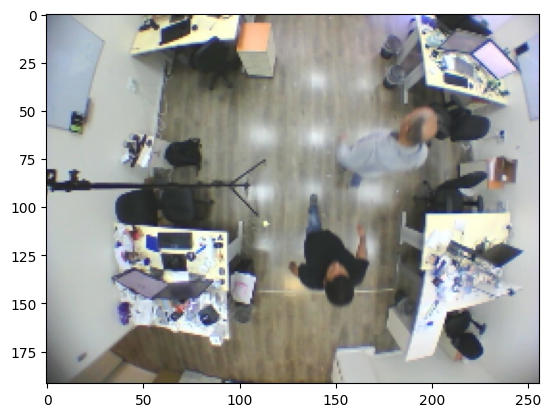

In [17]:
img = cv2.cvtColor(np.transpose(sample[0].copy(), (1, 2, 0)).astype(np.uint8), cv2.COLOR_BGR2RGB)
plt.imshow(img)

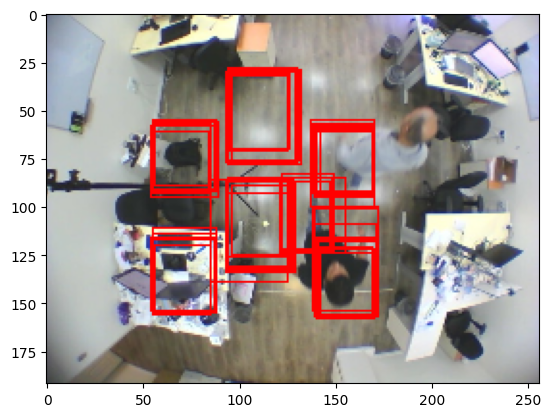

In [18]:
scores = float_predictions[:, -1] * float_predictions[:, -2]

boxes = float_predictions[scores > 0.1][:, :4].copy()
boxes_xyxy = np.ones_like(boxes)
boxes_xyxy[:, 0] = boxes[:, 0] - boxes[:, 2]/2.
boxes_xyxy[:, 1] = boxes[:, 1] - boxes[:, 3]/2.
boxes_xyxy[:, 2] = boxes[:, 0] + boxes[:, 2]/2.
boxes_xyxy[:, 3] = boxes[:, 1] + boxes[:, 3]/2.
boxes_xyxy = boxes_xyxy.astype(int)

tmp = img.copy()
for box in boxes_xyxy:
    cv2.rectangle(tmp, box[:2], box[2:], (255, 0, 0), 1)

plt.imshow(tmp)

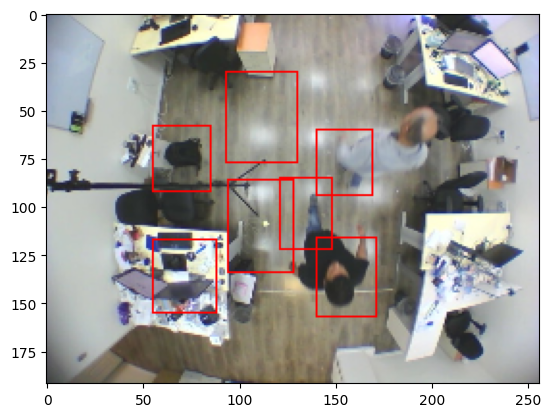

In [19]:
dets = post_process(float_out, 1, (192, 256))
tmp = img.copy()
for box in dets[:,:4].astype(int):
    cv2.rectangle(tmp, box[:2], box[2:], (255, 0, 0), 1)

plt.imshow(tmp)

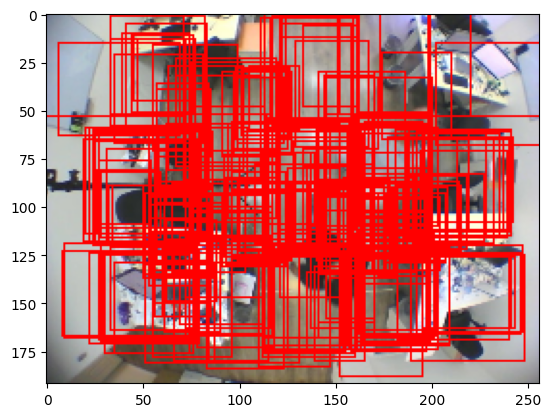

In [20]:
scores = quant_predictions[:, -1] * quant_predictions[:, -2]

boxes = quant_predictions[scores > 0.01][:, :4].copy()
boxes_xyxy = np.ones_like(boxes)
boxes_xyxy[:, 0] = boxes[:, 0] - boxes[:, 2]/2.
boxes_xyxy[:, 1] = boxes[:, 1] - boxes[:, 3]/2.
boxes_xyxy[:, 2] = boxes[:, 0] + boxes[:, 2]/2.
boxes_xyxy[:, 3] = boxes[:, 1] + boxes[:, 3]/2.
boxes_xyxy = boxes_xyxy.astype(int)

tmp = img.copy()
for box in boxes_xyxy:
    cv2.rectangle(tmp, box[:2], box[2:], (255, 0, 0), 1)

plt.imshow(tmp)

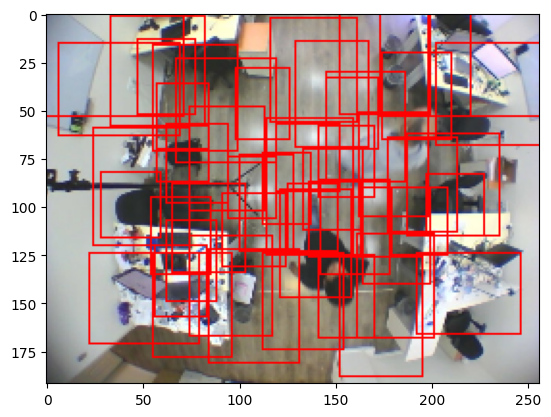

In [21]:
dets = post_process(quant_out, 1, (192, 256), score_thr=0.01)
tmp = img.copy()
for box in dets[:,:4].astype(int):
    cv2.rectangle(tmp, box[:2], box[2:], (255, 0, 0), 1)

plt.imshow(tmp)

In [22]:
flout = G.execute(sample)
dqout = G.execute(sample, dequantize=True)
qqout = G.execute(sample, dequantize=False, quantize=True)

onode = G["output_1"]

float_boxes = flout[onode.step_idx][0]
quant_boxes = dqout[onode.step_idx][0]
strides = [8, 16, 32]
feature_map_sizes = [(24, 32), (12, 16), (6, 8)]
decoded_float_boxes = decode_C_style(float_boxes.flatten(), feature_map_sizes, strides)
decoded_quant_boxes = decode_C_style(quant_boxes.flatten(), feature_map_sizes, strides)

In [23]:
decoded_float_boxes = decoded_float_boxes.reshape(-1, 6)
decoded_quant_boxes = decoded_quant_boxes.reshape(-1, 6)

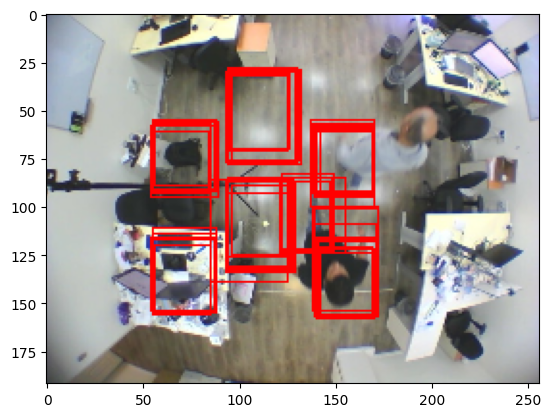

In [24]:
scores = decoded_float_boxes[:, -1] * decoded_float_boxes[:, -2]

boxes = decoded_float_boxes[scores > 0.1][:, :4].copy()
boxes_xyxy = np.ones_like(boxes)
boxes_xyxy[:, 0] = boxes[:, 0] - boxes[:, 2]/2.
boxes_xyxy[:, 1] = boxes[:, 1] - boxes[:, 3]/2.
boxes_xyxy[:, 2] = boxes[:, 0] + boxes[:, 2]/2.
boxes_xyxy[:, 3] = boxes[:, 1] + boxes[:, 3]/2.
boxes_xyxy = boxes_xyxy.astype(int)

tmp = img.copy()
for box in boxes_xyxy:
    cv2.rectangle(tmp, box[:2], box[2:], (255, 0, 0), 1)

plt.imshow(tmp)

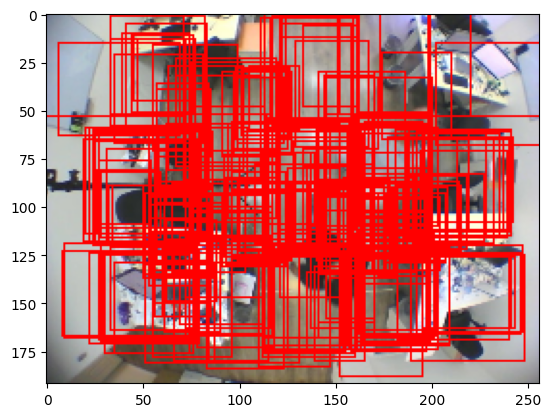

In [25]:
scores = decoded_quant_boxes[:, -1] * decoded_quant_boxes[:, -2]

boxes = decoded_quant_boxes[scores > 0.01][:, :4].copy()
boxes_xyxy = np.ones_like(boxes)
boxes_xyxy[:, 0] = boxes[:, 0] - boxes[:, 2]/2.
boxes_xyxy[:, 1] = boxes[:, 1] - boxes[:, 3]/2.
boxes_xyxy[:, 2] = boxes[:, 0] + boxes[:, 2]/2.
boxes_xyxy[:, 3] = boxes[:, 1] + boxes[:, 3]/2.
boxes_xyxy = boxes_xyxy.astype(int)

tmp = img.copy()
for box in boxes_xyxy:
    cv2.rectangle(tmp, box[:2], box[2:], (255, 0, 0), 1)

plt.imshow(tmp)

In [26]:
score_thr = 0.1
# input_shape = 416, 416
input_shape = 192, 256

img_paths = [
    "../../../YOLOX/datasets/pg_coco/val2017/H265_test_office_2_20fps_N00019__9010.jpg",
    "../../../YOLOX/datasets/pg_coco/val2017/RegusPodil_H275_Cam3_meeting_5HO_STATIC_20fps_r1_20220202_142755__759.jpg",
    "../../../YOLOX/datasets/pg_coco/val2017/H265_Cam2_vayyar_init_subtraction_20fps_black_20211202_165234_N00021__60.jpg",
    "../../../YOLOX/datasets/pg_coco/test2017/H247_JCI_newtest_4_N00013__1839.jpg",
    "../../../YOLOX/datasets/pg_coco/test2017/BeeWorking_H245_Cam3_meeting_5HO_STATIC_20fps_r1_20220201_135602_10fps__1184.jpg"
    
]
img_path = img_paths[4]
origin_img = cv2.imread(img_path)
img, ratio = preprocess(origin_img, input_shape)

img = np.transpose(img, (1, 2, 0))

In [27]:
img.shape

(192, 256, 3)

In [28]:
float_execution = G.execute([img], quantize=False)
quant_execution = G.execute([img], quantize=True, dequantize=True)

In [29]:
from nntool.graph.types import ConstantInputNode
qsnrs_by_layer = G.qsnrs(float_execution, quant_execution)
print("QSNR layer by layer (skipping constant layers like weights and biases):")
print(f"{'Layer Name':>30} (  #): {'QSNR':4}")
for i, q in enumerate(qsnrs_by_layer):
    if isinstance(G[i], ConstantInputNode):
        continue
    print(f"{G[i].name:>30} ({i:3}): {q:4}")

QSNR layer by layer (skipping constant layers like weights and biases):
                    Layer Name (  #): QSNR
                       input_1 (  0):  inf
 _backbone_backbone_stem_Slice (  1):  inf
_backbone_backbone_stem_Slice_1 (  2):  inf
_backbone_backbone_stem_Slice_2 (  3):  inf
_backbone_backbone_stem_Slice_3 (  4):  inf
_backbone_backbone_stem_Slice_4 (  5):  inf
_backbone_backbone_stem_Slice_5 (  6):  inf
_backbone_backbone_stem_Concat (  7):  inf
_backbone_backbone_stem_conv_conv_Conv_fusion_qin0 (  8):  inf
_backbone_backbone_stem_conv_conv_Conv_fusion ( 11):   12
_backbone_backbone_dark2_dark2_0_dconv_conv_Conv_fusion ( 14):   18
_backbone_backbone_dark2_dark2_0_pconv_conv_Conv_fusion ( 17):    7
_backbone_backbone_dark2_dark2_1_conv1_conv_Conv_fusion ( 20):   11
_backbone_backbone_dark2_dark2_1_conv1_conv_Conv_split ( 21):   11
_backbone_backbone_dark2_dark2_1_Concat_qin1 ( 22):   10
_backbone_backbone_dark2_dark2_1_m_m_0_conv1_conv_Conv_fusion ( 25):    7
_backbone_bac

In [30]:
float_out = [float_execution[out_node.step_idx][0] for out_node in G.outputs()]
quant_out = [quant_execution[out_node.step_idx][0] for out_node in G.outputs()]

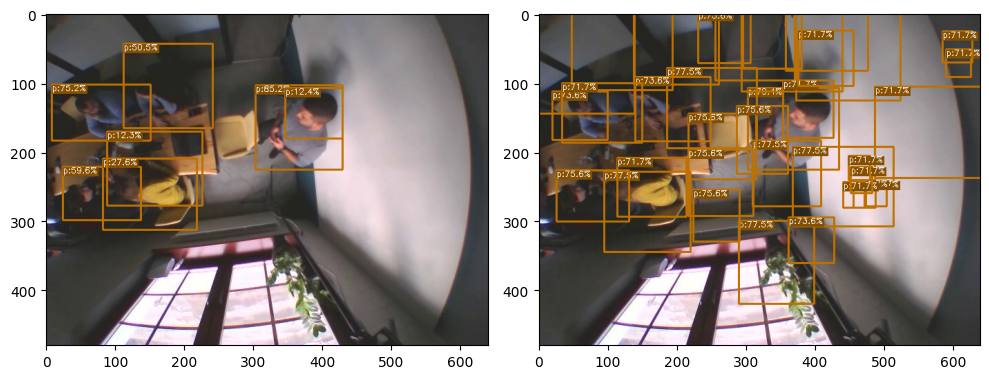

In [31]:
dets = post_process(float_out, 0.4, input_shape)
if dets is not None:
    final_boxes, final_scores, final_cls_inds = dets[:, :4], dets[:, 4], dets[:, 5]
    img_a = vis(origin_img.copy(), final_boxes, final_scores, final_cls_inds,
                        conf=score_thr, class_names=("person"))
    

dets = post_process(quant_out, 0.4, input_shape, mul_scores=False, score_thr=0.7)
if dets is not None:
    final_boxes, final_scores, final_cls_inds = dets[:, :4], dets[:, 4], dets[:, 5]
    img_b = vis(origin_img.copy(), final_boxes, final_scores, final_cls_inds,
                        conf=score_thr, class_names=("person"))

plt.figure(figsize=(10, 7))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_a, cv2.COLOR_BGR2RGB))
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img_b, cv2.COLOR_BGR2RGB))
plt.tight_layout()

In [38]:
quant_dataset = YOLOXCOCODaset(
    image_folder     = "../../../YOLOX/datasets/pg_coco/test2017",
    annotations      = annotations,
    max_size         = 250,
    input_size       = (192, 256),
    transpose_to_chw = False,
    input_channels   = 3,
    img_type         = "rgb",
    enable_slicing   = False
)

/host/gap_sdk_private/tools/nntool/nntool/execution/kernels/float/activations.py:77: RuntimeWarning: overflow encountered in exp
  return qrec.get_outputs(params, [in_dtype(1) / (in_dtype(1) + np.exp(-in_tensor).astype(in_dtype))], ktype="float")


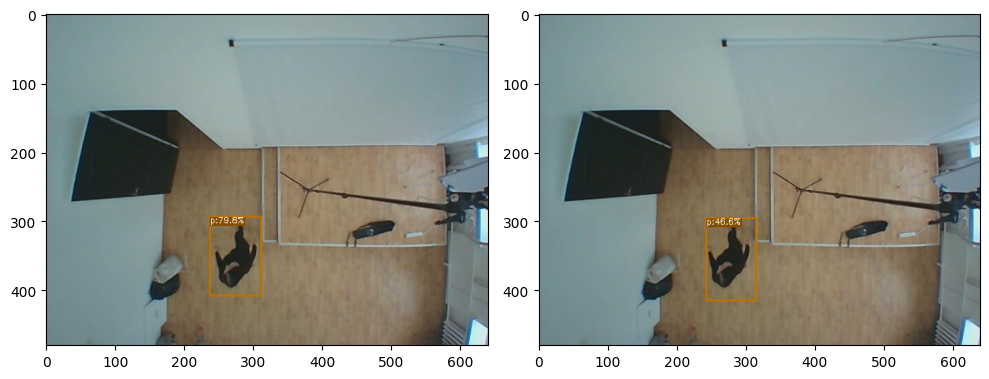

In [50]:
input_data = next(quant_dataset)
# input_data[0] = cv2.cvtColor(input_data[0], cv2.COLOR_BGR2RGB)

float_execution = G.execute(input_data, quantize=False)
float_out = [float_execution[out_node.step_idx][0] for out_node in G.outputs()]

quant_execution = G.execute(input_data, dequantize=True)
quant_out = [quant_execution[out_node.step_idx][0] for out_node in G.outputs()]

origin_img = quant_dataset._img

dets = post_process(float_out, 0.4, input_shape, 0.1, mul_scores=True)
if dets is not None:
    final_boxes, final_scores, final_cls_inds = dets[:, :4], dets[:, 4], dets[:, 5]
    img_a = vis(origin_img.copy(), final_boxes, final_scores, final_cls_inds,
                        conf=score_thr, class_names=("person"))
    

dets = post_process(quant_out, 0.4, input_shape, 0.1, mul_scores=True)
if dets is not None:
    final_boxes, final_scores, final_cls_inds = dets[:, :4], dets[:, 4], dets[:, 5]
    img_b = vis(origin_img.copy(), final_boxes, final_scores, final_cls_inds,
                        conf=score_thr, class_names=("person"))
else:
    img_b = origin_img.copy()

plt.figure(figsize=(10, 7))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_a, cv2.COLOR_BGR2RGB))
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img_b, cv2.COLOR_BGR2RGB))
plt.tight_layout()

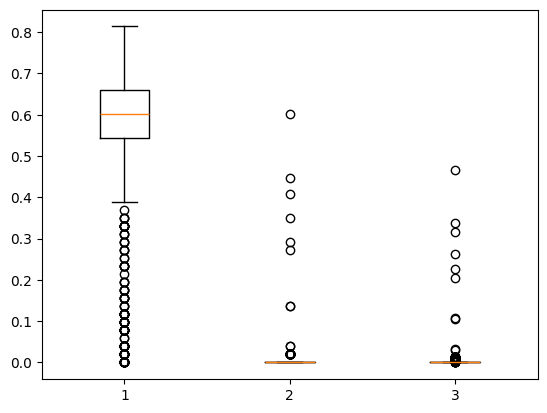

In [51]:
predictions = demo_postprocess(quant_out[0].copy()[None, :], input_shape)[0]
plt.boxplot([predictions[:, -1], predictions[:, -2], predictions[:, -2] * predictions[:, -1]]);

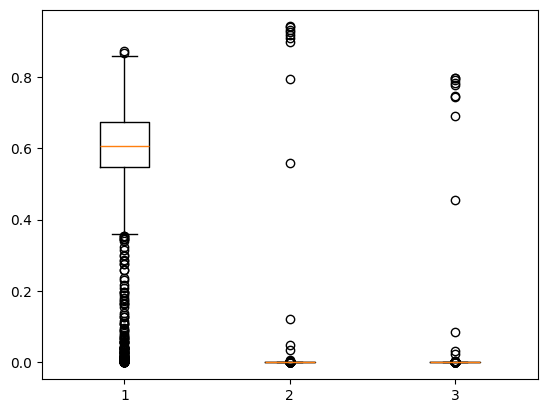

In [52]:
predictions = demo_postprocess(float_out[0].copy()[None, :], input_shape)[0]
plt.boxplot([predictions[:, -1], predictions[:, -2], predictions[:, -2] * predictions[:, -1]]);

In [54]:
# On the target only fully integer values - NO DEQUANTIZE
sample = next(quant_dataset)
int_execution = G.execute(sample, dequantize=False, quantize=True)
G[0].at_options.allocate = 1
G[0].at_options

{'ALLOCATE': 1}

In [56]:
work_dir = "/tmp/test_tutorial"
res = G.execute_on_target(
    pmsis_os='freertos',
    platform="gvsoc",
    directory=work_dir,
    input_tensors=int_execution[0],
    output_tensors=0,
    write_out_to_file=True,
    at_log=True,
    dont_run=False,
    do_clean=False,
    cmake=True,
    at_loglevel=2,
    print_output=True,
    settings={
        "l1_size": 128000,
        "l2_size": 1000000,

        "graph_monitor_cycles": True,
        "graph_produce_node_names": True,
        "graph_produce_operinfos": True,
        "graph_const_exec_from_flash": True,
    }
)

Script started, output log file is '/tmp/tmpgd5ifcby/log.txt'.
-- [Custom BSP] Custom BSP unused.
-- [Python] Interpreter found here /usr/bin/python3.10
-- [Kconfig] KCONFIG_CONFIG environnement variable has not been exported.
-- [Kconfig] Using default value sdk: "sdk.config" and app: "sdk.config".
-- [NNTOOL] Using nntool in /gap_sdk_private/tools/nntool/scripts/nntool
-- [SFU] Using SFU in 
-- [DT] Formating configuration file
-- [DT] Selected options : gap9_v2_wlcsp;gap9mod_v1_0_b;gap9evk_v1_3
-- [DT] Compiling gap9_v2_wlcsp.dts
-- [DT] Compiling gap9mod_v1_0_b.dts
-- [DT] Compiling gap9evk_v1_3.dts
-- [DT] Dumping C header file
-- [Board] GAP Family : 9
-- [Board] GAP Version : 2
-- [AutoTiler] Using SQ8 kernels
-- [AutoTiler] Using FP16 kernels
-- [AutoTiler] Using NE16 kernels
-- [AutoTiler] Using Default Flash
-- [AutoTiler] Using Default RAM
-- [Compiler] Compiling for FreeRTOS on riscv32 using compiler found at /usr/lib/gap_riscv_toolchain/bin/riscv32-unknown-elf-gcc
-- [Auto